## Using 50-50 representation of both delivered and returned labels (2.5 M rows from each labels)

**Selecting features and initialization of dataframe**

In [ ]:
import pandas as pd
df=pd.read_parquet("ecommerce_5M_balanced.parquet")

In [4]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    confusion_matrix,
    classification_report
)


# ============================================================
# 2. CONFIGURATION
# ============================================================

TARGET = "return_target"

# Business objective: catch at least 80% of returns.
TARGET_RECALL = 0.80

# Minimum threshold to consider during optimization.
MIN_THRESHOLD = 0.01

RANDOM_STATE = 42

# If your dataset is very large, you can reduce this to 20.
TOP_N_FEATURES = 25


# ============================================================
# 3. FEATURE ENGINEERING
# ============================================================

def create_engineered_features(data):

    data = data.copy()

    category = (
        data["product_category"]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    # Free shipping indicator
    data["is_free_shipping"] = (
        data["shipping_cost"] == 0
    ).astype("int8")

    # Product category indicators
    # data["is_clothing"] = (
    #     category == "clothing"
    # ).astype("int8")

    # data["is_electronics"] = (
    #     category == "electronics"
    # ).astype("int8")

    # Expensive clothing indicator
    data["clothing_expensive"] = (
        (category == "clothing") &
        (data["unit_price"] > 75)
    ).astype("int8")

    # Shipping cost as a proportion of order total
    data["shipping_ratio"] = np.divide(
        data["shipping_cost"],
        data["order_total"],
        out=np.zeros(len(data), dtype=float),
        where=data["order_total"].to_numpy() != 0
    )

    # Expected subtotal before shipping/discount adjustments
    data["expected_subtotal"] = (
        data["quantity"] * data["unit_price"]
    )

    # Effective unit price after subtracting shipping
    data["effective_unit_price"] = np.divide(
        data["order_total"] - data["shipping_cost"],
        data["quantity"],
        out=np.zeros(len(data), dtype=float),
        where=data["quantity"].to_numpy() != 0
    )

    # Single-item order indicator
    data["is_single_item"] = (
        data["quantity"] == 1
    ).astype("int8")

    # Difference between observed total and expected subtotal + shipping
    data["price_diff"] = (
        data["order_total"] -
        (data["expected_subtotal"] + data["shipping_cost"])
    )

    # # Extract date features available at order placement
    # if "order_date" in data.columns:

    #     order_date = pd.to_datetime(
    #         data["order_date"],
    #         errors="coerce"
    #     )

    #     data["order_month"] = order_date.dt.month
    #     data["order_dayofweek"] = order_date.dt.dayofweek

    #     # Drop raw date after extracting useful features
    #     data.drop(columns=["order_date"], inplace=True)

    return data


df = create_engineered_features(df)


# ============================================================
# 4. PREPARE TARGET AND FEATURES
# ============================================================

# Keep only completed outcomes for this binary classification task.
# This assumes order_status is available and uses these exact labels.
if "order_status" in df.columns:

    df = df[
        df["order_status"]
        .astype("string")
        .str.strip()
        .str.lower()
        .isin(["returned", "delivered"])
    ].copy()

# Safely reconstruct return_target if it is missing from df
if TARGET not in df.columns and "order_status" in df.columns:
    df[TARGET] = (df["order_status"].astype(str).str.strip().str.lower() == "returned").astype("int8")

# Ensure target is binary
df = df.dropna(subset=[TARGET]).copy()
df[TARGET] = df[TARGET].astype("int8")

X = df.drop(columns=[TARGET])
y = df[TARGET]

# Explicitly remove columns that should not be model predictors.
# order_status is the outcome label source, not an order-placement feature.
columns_to_drop = [
    "order_status",
    "order_id",
    "customer_id",
    "product_id"
]

X = X.drop(
    columns=[c for c in columns_to_drop if c in X.columns],
    errors="ignore"
)

print("Dataset shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts())
print("\nTarget proportions:")
print(y.value_counts(normalize=True))


# ============================================================
# 5. STRATIFIED 70-15-15 SPLIT
# ============================================================

# First split: 70% train, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE
)

# Second split: split temporary data equally into validation/test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=RANDOM_STATE
)

print("\nSplit sizes:")
print(f"Training:   {len(X_train):,} ({len(X_train) / len(X):.1%})")
print(f"Validation: {len(X_val):,} ({len(X_val) / len(X):.1%})")
print(f"Testing:    {len(X_test):,} ({len(X_test) / len(X):.1%})")

print("\nReturn rates by split:")
print(f"Train:      {y_train.mean():.4%}")
print(f"Validation: {y_val.mean():.4%}")
print(f"Test:       {y_test.mean():.4%}")

Dataset shape: (5000000, 15)

Target distribution:
return_target
0    2500000
1    2500000
Name: count, dtype: int64

Target proportions:
return_target
0    0.5
1    0.5
Name: proportion, dtype: float64

Split sizes:
Training:   3,500,000 (70.0%)
Validation: 750,000 (15.0%)
Testing:    750,000 (15.0%)

Return rates by split:
Train:      50.0000%
Validation: 50.0000%
Test:       50.0000%


**Preprocessing of both Target and predictors**

In [9]:
# ============================================================
#  PREPROCESSING
# ============================================================

categorical_features = [
    "product_category",
    "payment_method",
    "discount_applied"
]

categorical_features = [
    col for col in categorical_features
    if col in X_train.columns
]

numeric_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

# Convert numeric columns and handle invalid values
for col in numeric_features:
    X_train[col] = pd.to_numeric(X_train[col], errors="coerce")
    X_val[col] = pd.to_numeric(X_val[col], errors="coerce")
    X_test[col] = pd.to_numeric(X_test[col], errors="coerce")

# Learn numeric medians from training data only
numeric_medians = X_train[numeric_features].median()

X_train[numeric_features] = X_train[numeric_features].fillna(numeric_medians)
X_val[numeric_features] = X_val[numeric_features].fillna(numeric_medians)
X_test[numeric_features] = X_test[numeric_features].fillna(numeric_medians)

# Handle categorical missing values
for col in categorical_features:
    X_train[col] = X_train[col].fillna("Unknown").astype(str)
    X_val[col] = X_val[col].fillna("Unknown").astype(str)
    X_test[col] = X_test[col].fillna("Unknown").astype(str)

# One-hot encode categorical variables
X_train = pd.get_dummies(X_train, columns=categorical_features, dtype=np.uint8)
X_val = pd.get_dummies(X_val, columns=categorical_features, dtype=np.uint8)
X_test = pd.get_dummies(X_test, columns=categorical_features, dtype=np.uint8)

# Align validation and test columns to training columns
X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# Ensure consistent column order
X_val = X_val[X_train.columns]
X_test = X_test[X_train.columns]

print("Processed feature matrix shapes:")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Processed feature matrix shapes:
Train: (3500000, 19)
Validation: (750000, 19)
Test: (750000, 19)


**Removing outliers**

In [10]:
# ============================================================
# OUTLIER CAPPING (IQR METHOD)
# ============================================================

outlier_features = ["quantity", "unit_price", "order_total", "shipping_cost"]
outlier_features = [col for col in outlier_features if col in X_train.columns]

print("Outlier distribution before capping (Train Set):\n")
for col in outlier_features:
    print(f"{col:20} - Min: {X_train[col].min():8.2f} | Max: {X_train[col].max():8.2f}")

# Calculate bounds using Train set metrics only
for col in outlier_features:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Cap features across all partitions
    X_train[col] = np.clip(X_train[col], lower_bound, upper_bound)
    X_val[col] = np.clip(X_val[col], lower_bound, upper_bound)
    X_test[col] = np.clip(X_test[col], lower_bound, upper_bound)

print("\nOutlier distribution after capping (Train Set):\n")
for col in outlier_features:
    print(f"{col:20} - Min: {X_train[col].min():8.2f} | Max: {X_train[col].max():8.2f}")

Outlier distribution before capping (Train Set):

quantity             - Min:     1.00 | Max:     3.50
unit_price           - Min:     2.02 | Max:   283.62
order_total          - Min:     6.22 | Max:   516.49
shipping_cost        - Min:     0.00 | Max:     9.99

Outlier distribution after capping (Train Set):

quantity             - Min:     1.00 | Max:     3.50
unit_price           - Min:     2.02 | Max:   283.62
order_total          - Min:     6.22 | Max:   516.49
shipping_cost        - Min:     0.00 | Max:     9.99


**Full training code**

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    confusion_matrix,
    classification_report
)

# ============================================================
# 1. CONFIGURATION
# ============================================================
TARGET = "return_target"
RANDOM_STATE = 42
TARGET_RECALL = 0.80
MIN_THRESHOLD = 0.01

# ============================================================
# 2. LOAD ORIGINAL DATASET
# ============================================================
# Read the original balanced dataset directly
df_orig = pd.read_parquet("ecommerce_5M_balanced.parquet")

# Keep only completed outcomes
df_orig = df_orig[df_orig["order_status"].isin(["delivered", "returned"])].copy()

# Construct target
df_orig[TARGET] = (df_orig["order_status"] == "returned").astype("int8")

print("Original Dataset Shape:", df_orig.shape)
print("Target Distribution:\n", df_orig[TARGET].value_counts(normalize=True))

# ============================================================
# 3. SEPARATE FEATURES AND TARGET (NO FEATURE ENGINEERING)
# ============================================================
# We only use original features, and drop non-predictor identifiers and outcome columns
original_predictors = [
    "product_category",
    "quantity",
    "unit_price",
    "order_total",
    "payment_method",
    "shipping_cost",
    "discount_applied"
]

X_orig = df_orig[original_predictors].copy()
y_orig = df_orig[TARGET].copy()

# ============================================================
# 4. STRATIFIED 70-15-15 SPLIT
# ============================================================
X_train, X_temp, y_train, y_temp = train_test_split(
    X_orig, y_orig, test_size=0.30, stratify=y_orig, random_state=RANDOM_STATE
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)

print(f"\nSplits -> Train: {X_train.shape[0]:,}, Val: {X_val.shape[0]:,}, Test: {X_test.shape[0]:,}")

# ============================================================
# 5. OUTLIER CAPPING (IQR METHOD ON ORIGINAL COLUMNS)
# ============================================================
outlier_features = ["quantity", "unit_price", "order_total", "shipping_cost"]

for col in outlier_features:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Cap partitions
    X_train[col] = np.clip(X_train[col], lower_bound, upper_bound)
    X_val[col] = np.clip(X_val[col], lower_bound, upper_bound)
    X_test[col] = np.clip(X_test[col], lower_bound, upper_bound)

# ============================================================
# 6. PREPROCESSING (IMPUTATION AND ONE-HOT ENCODING)
# ============================================================
categorical_features = ["product_category", "payment_method", "discount_applied"]
numeric_features = [col for col in X_train.columns if col not in categorical_features]

# Convert numeric columns
for col in numeric_features:
    X_train[col] = pd.to_numeric(X_train[col], errors="coerce")
    X_val[col] = pd.to_numeric(X_val[col], errors="coerce")
    X_test[col] = pd.to_numeric(X_test[col], errors="coerce")

# Learn and fill medians
numeric_medians = X_train[numeric_features].median()
X_train[numeric_features] = X_train[numeric_features].fillna(numeric_medians)
X_val[numeric_features] = X_val[numeric_features].fillna(numeric_medians)
X_test[numeric_features] = X_test[numeric_features].fillna(numeric_medians)

# Categorical fillna
for col in categorical_features:
    X_train[col] = X_train[col].fillna("Unknown").astype(str)
    X_val[col] = X_val[col].fillna("Unknown").astype(str)
    X_test[col] = X_test[col].fillna("Unknown").astype(str)

# One-hot encode
X_train = pd.get_dummies(X_train, columns=categorical_features, dtype=np.uint8)
X_val = pd.get_dummies(X_val, columns=categorical_features, dtype=np.uint8)
X_test = pd.get_dummies(X_test, columns=categorical_features, dtype=np.uint8)

# Align columns
X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Processed feature shape:", X_train.shape)

# ============================================================
# 7. MODEL TRAINING (UNWEIGHTED AND WEIGHTED)
# ============================================================
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_pos_weight = negative_count / positive_count

common_params = {
    "objective": "binary",
    "boosting_type": "gbdt",
    "n_estimators": 1000,
    "learning_rate": 0.03,
    "num_leaves": 31,
    "max_depth": 8,
    "min_child_samples": 50,
    "colsample_bytree": 0.8,
    "subsample": 0.8,
    "subsample_freq": 1,
    "max_bin": 127,
    "reg_alpha": 0.1,
    "reg_lambda": 1.0,
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
    "verbosity": -1
}

print("\nTraining Unweighted Model...")
model_unweighted = lgb.LGBMClassifier(**common_params)
model_unweighted.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="auc",
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(100)]
)

print("\nTraining Weighted Model...")
model_weighted = lgb.LGBMClassifier(**common_params, scale_pos_weight=scale_pos_weight)
model_weighted.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="auc",
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(100)]
)

# ============================================================
# 8. EVALUATION & THRESHOLD OPTIMIZATION
# ============================================================
val_probs_unweighted = model_unweighted.predict_proba(X_val)[:, 1]
val_probs_weighted = model_weighted.predict_proba(X_val)[:, 1]

auc_unweighted = roc_auc_score(y_val, val_probs_unweighted)
auc_weighted = roc_auc_score(y_val, val_probs_weighted)
print(f"\nUnweighted Model AUC: {auc_unweighted:.4f} | Weighted Model AUC: {auc_weighted:.4f}")

# Select the model to use
model = model_weighted
val_probabilities = val_probs_weighted

# Optimize threshold
thresholds = np.arange(MIN_THRESHOLD, 0.501, 0.01)
threshold_results = []

for threshold in thresholds:
    val_predictions = (val_probabilities >= threshold).astype("int8")
    precision = precision_score(y_val, val_predictions, zero_division=0)
    recall = recall_score(y_val, val_predictions, zero_division=0)
    f1 = f1_score(y_val, val_predictions, zero_division=0)
    accuracy = accuracy_score(y_val, val_predictions)

    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

threshold_df = pd.DataFrame(threshold_results)
eligible_thresholds = threshold_df[threshold_df["recall"] >= TARGET_RECALL]

if not eligible_thresholds.empty:
    best_row = eligible_thresholds.sort_values(by=["precision", "threshold"], ascending=[False, False]).iloc[0]
    BEST_THRESHOLD = float(best_row["threshold"])
    print(f"\nSelected Threshold for {TARGET_RECALL:.0%} Recall: {BEST_THRESHOLD:.3f}")
else:
    best_row = threshold_df.sort_values(by=["recall", "precision"], ascending=[False, False]).iloc[0]
    BEST_THRESHOLD = float(best_row["threshold"])
    print(f"\nCould not meet {TARGET_RECALL:.0%} recall. Choosing max recall threshold: {BEST_THRESHOLD:.3f}")

# ============================================================
# 9. EVALUATE ON TEST DATA
# ============================================================
test_probabilities = model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= BEST_THRESHOLD).astype("int8")

print("\n" + "="*40)
print("FINAL TEST METRICS (ONLY ORIGINAL COLUMNS)")
print("="*40)
print(f"Accuracy:          {accuracy_score(y_test, test_predictions):.4f}")
print(f"Recall:            {recall_score(y_test, test_predictions):.4f}")
print(f"Precision:         {precision_score(y_test, test_predictions):.4f}")
print(f"F1 Score:          {f1_score(y_test, test_predictions):.4f}")
print(f"ROC AUC Score:     {roc_auc_score(y_test, test_probabilities):.4f}")


Original Dataset Shape: (5000000, 13)
Target Distribution:
 return_target
0    0.5
1    0.5
Name: proportion, dtype: float64

Splits -> Train: 3,500,000, Val: 750,000, Test: 750,000
Processed feature shape: (3500000, 19)

Training Unweighted Model...
Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.68533	valid_0's binary_logloss: 0.634614
Early stopping, best iteration is:
[25]	valid_0's auc: 0.685522	valid_0's binary_logloss: 0.650026

Training Weighted Model...
Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.68533	valid_0's binary_logloss: 0.634614
Early stopping, best iteration is:
[25]	valid_0's auc: 0.685522	valid_0's binary_logloss: 0.650026

Unweighted Model AUC: 0.6855 | Weighted Model AUC: 0.6855

Selected Threshold for 80% Recall: 0.460

FINAL TEST METRICS (ONLY ORIGINAL COLUMNS)
Accuracy:          0.6207
Recall:            0.8229
Precision:         0.5860
F1 Score:          0.6845
ROC AUC Score:     0.6

**Hyperparameter optimization**

In [12]:

from sklearn.model_selection import RandomizedSearchCV
import lightgbm as lgb

# 1. Take a 10% stratified subsample for fast tuning
_, X_tune_sub, _, y_tune_sub = train_test_split(
    X_train, y_train,
    test_size=0.10,
    stratify=y_train,
    random_state=RANDOM_STATE
)

print(f"Tuning on a representative subset of size: {X_tune_sub.shape[0]:,}")

# 2. Define the hyperparameter search space
param_dist = {
    'num_leaves': [15, 31, 63, 127],
    'max_depth': [4, 6, 8, -1],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'min_child_samples': [20, 50, 100, 200],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'subsample': [0.6, 0.8, 1.0],
    'reg_alpha': [0.0, 0.1, 1.0, 5.0],
    'reg_lambda': [0.0, 0.1, 1.0, 5.0]
}

# 3. Initialize the base estimator
base_lgb = lgb.LGBMClassifier(
    objective='binary',
    boosting_type='gbdt',
    n_estimators=300,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=-1
)

# 4. Run RandomizedSearchCV targeting ROC-AUC
random_search = RandomizedSearchCV(
    estimator=base_lgb,
    param_distributions=param_dist,
    n_iter=15,
    scoring='roc_auc',
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

print("Starting randomized hyperparameter search...")
random_search.fit(X_tune_sub, y_tune_sub)

print("\nBest Hyperparameters Found:")
for param, value in random_search.best_params_.items():
    print(f"- {param}: {value}")

print(f"Best CV ROC-AUC: {random_search.best_score_:.4f}")

# Update our parameters for final training
optimized_params = common_params.copy()
optimized_params.update(random_search.best_params_)
print("\nOptimized parameters successfully prepared for final model training!")

Tuning on a representative subset of size: 350,000
Starting randomized hyperparameter search...
Fitting 3 folds for each of 15 candidates, totalling 45 fits

Best Hyperparameters Found:
- subsample: 1.0
- reg_lambda: 1.0
- reg_alpha: 5.0
- num_leaves: 31
- min_child_samples: 20
- max_depth: 6
- learning_rate: 0.01
- colsample_bytree: 0.6
Best CV ROC-AUC: 0.6843

Optimized parameters successfully prepared for final model training!


**Evaluation metrics**

Training Unweighted Model with Optimized Parameters...
Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.685282	valid_0's binary_logloss: 0.647145
[200]	valid_0's auc: 0.68535	valid_0's binary_logloss: 0.637296
[300]	valid_0's auc: 0.685419	valid_0's binary_logloss: 0.635086
[400]	valid_0's auc: 0.685453	valid_0's binary_logloss: 0.63454
Early stopping, best iteration is:
[368]	valid_0's auc: 0.685455	valid_0's binary_logloss: 0.63464

Training Weighted Model with Optimized Parameters...
Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.685282	valid_0's binary_logloss: 0.647145
[200]	valid_0's auc: 0.68535	valid_0's binary_logloss: 0.637296
[300]	valid_0's auc: 0.685419	valid_0's binary_logloss: 0.635086
[400]	valid_0's auc: 0.685453	valid_0's binary_logloss: 0.63454
Early stopping, best iteration is:
[368]	valid_0's auc: 0.685455	valid_0's binary_logloss: 0.63464

Selected Threshold for 80% Recall: 0.430


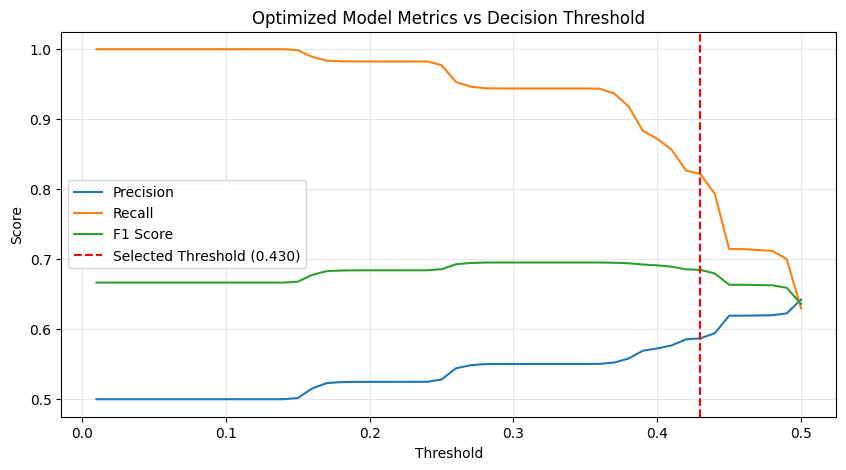


FINAL TEST METRICS (WITH OPTIMIZED HYPERPARAMETERS)
Accuracy:          0.6211
Recall:            0.8209


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Train unweighted model using optimized hyperparameters
print("Training Unweighted Model with Optimized Parameters...")
model_unweighted = lgb.LGBMClassifier(**optimized_params)
model_unweighted.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="auc",
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(100)]
)

# Train weighted model using optimized hyperparameters
print("\nTraining Weighted Model with Optimized Parameters...")
model_weighted = lgb.LGBMClassifier(**optimized_params, scale_pos_weight=scale_pos_weight)
model_weighted.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="auc",
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(100)]
)

# Select the weighted model as final candidate
model = model_weighted
val_probabilities = model.predict_proba(X_val)[:, 1]

# Optimize Decision Threshold to hit 80% recall target
thresholds = np.arange(MIN_THRESHOLD, 0.501, 0.01)
threshold_results = []

for threshold in thresholds:
    val_predictions = (val_probabilities >= threshold).astype("int8")
    precision = precision_score(y_val, val_predictions, zero_division=0)
    recall = recall_score(y_val, val_predictions, zero_division=0)
    f1 = f1_score(y_val, val_predictions, zero_division=0)
    accuracy = accuracy_score(y_val, val_predictions)

    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

threshold_df = pd.DataFrame(threshold_results)
eligible_thresholds = threshold_df[threshold_df["recall"] >= TARGET_RECALL]

if not eligible_thresholds.empty:
    best_row = eligible_thresholds.sort_values(by=["precision", "threshold"], ascending=[False, False]).iloc[0]
    BEST_THRESHOLD = float(best_row["threshold"])
    print(f"\nSelected Threshold for {TARGET_RECALL:.0%} Recall: {BEST_THRESHOLD:.3f}")
else:
    best_row = threshold_df.sort_values(by=["recall", "precision"], ascending=[False, False]).iloc[0]
    BEST_THRESHOLD = float(best_row["threshold"])
    print(f"\nCould not meet {TARGET_RECALL:.0%} recall. Choosing max recall threshold: {BEST_THRESHOLD:.3f}")

# Plot Metrics vs Decision Threshold
plt.figure(figsize=(10, 5))
plt.plot(threshold_df["threshold"], threshold_df["precision"], label="Precision")
plt.plot(threshold_df["threshold"], threshold_df["recall"], label="Recall")
plt.plot(threshold_df["threshold"], threshold_df["f1"], label="F1 Score")
plt.axvline(BEST_THRESHOLD, linestyle="--", color="red", label=f"Selected Threshold ({BEST_THRESHOLD:.3f})")
plt.title("Optimized Model Metrics vs Decision Threshold")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Evaluate on final test set
test_probabilities = model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= BEST_THRESHOLD).astype("int8")

print("\n" + "="*50)
print("FINAL TEST METRICS (WITH OPTIMIZED HYPERPARAMETERS)")
print("="*50)
print(f"Accuracy:          {accuracy_score(y_test, test_predictions):.4f}")
print(f"Recall:            {recall_score(y_test, test_predictions):.4f}")
# print(f

**Different threshold and their costs**

=== TOP THRESHOLD CANDIDATES GUARANTEEING >= 80% RECALL ===


,Threshold,Accuracy,Precision,Recall,F1-Score,False Positives (FP),False Negatives (FN),Estimated Cost ($)
27,0.435,0.621847,0.587104,0.821283,0.684724,216596,67019,1438477.0
26,0.430,0.621732,0.586940,0.821821,0.684800,216884,66817,1436023.0
25,0.425,0.621619,0.586746,0.822621,0.684945,217269,66517,1432293.0
24,0.420,0.620788,0.585564,0.826619,0.685518,219391,65018,1414052.0
23,0.415,0.618413,0.582408,0.836869,0.686828,225016,61174,1367642.0
22,0.410,0.614103,0.576867,0.856315,0.689347,235541,53882,1279312.0
21,0.405,0.611663,0.573889,0.867275,0.690719,241481,49772,1229542.0
20,0.400,0.610489,0.572544,0.872021,0.691240,244141,47992,1208162.0
19,0.395,0.609161,0.571067,0.877173,0.691771,247069,46060,1185038.0
18,0.390,0.607528,0.569290,0.883456,0.692403,250650,43704,1156860.0



=== THRESHOLD THAT MINIMIZES TOTAL BUSINESS LOSS ===
Optimal Cost Threshold: 0.300
Recall:                 0.9439
Precision:              0.5504
Estimated Loss:        $893,785.00


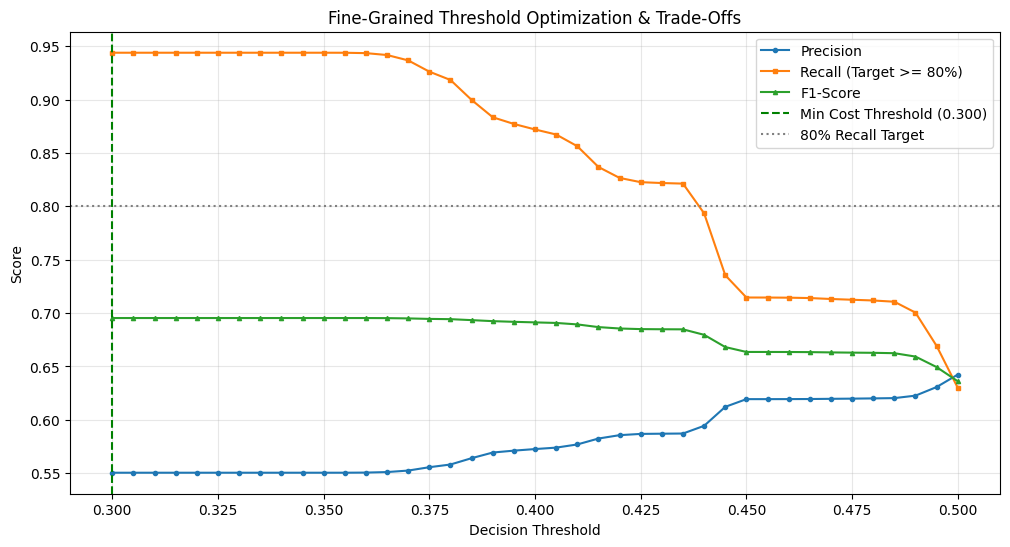

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix

# Define granular thresholds to scan
fine_thresholds = np.arange(0.30, 0.501, 0.005)
fine_results = []

# Assume a business cost scenario:
# Let's say a False Negative (missed return) costs the business $15 (shipping, processing, lost inventory value)
# A False Positive (unnecessary warning/flag) costs only $2 (manual inspection or friction cost)
COST_FN = 15.0
COST_FP = 2.0

for threshold in fine_thresholds:
    val_preds = (val_probabilities >= threshold).astype("int8")

    precision = precision_score(y_val, val_preds, zero_division=0)
    recall = recall_score(y_val, val_preds, zero_division=0)
    f1 = f1_score(y_val, val_preds, zero_division=0)
    accuracy = accuracy_score(y_val, val_preds)

    # Calculate Confusion Matrix to estimate financial impact
    tn, fp, fn, tp = confusion_matrix(y_val, val_preds).ravel()
    total_loss = (fn * COST_FN) + (fp * COST_FP)

    fine_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "False Positives (FP)": fp,
        "False Negatives (FN)": fn,
        "Estimated Cost ($)": total_loss
    })

fine_df = pd.DataFrame(fine_results)

# Filter scenarios where we hit at least 80% Recall
eligible_fine = fine_df[fine_df["Recall"] >= 0.80]

print("=== TOP THRESHOLD CANDIDATES GUARANTEEING >= 80% RECALL ===")
display(eligible_fine.sort_values(by="Precision", ascending=False).head(10))

print("\n=== THRESHOLD THAT MINIMIZES TOTAL BUSINESS LOSS ===")
best_cost_row = fine_df.sort_values(by="Estimated Cost ($)").iloc[0]
print(f"Optimal Cost Threshold: {best_cost_row['Threshold']:.3f}")
print(f"Recall:                 {best_cost_row['Recall']:.4f}")
print(f"Precision:              {best_cost_row['Precision']:.4f}")
print(f"Estimated Loss:        ${best_cost_row['Estimated Cost ($)']:,.2f}")

# Plot the detailed metrics trade-off
plt.figure(figsize=(12, 6))
plt.plot(fine_df["Threshold"], fine_df["Precision"], label="Precision", marker='o', markersize=3)
plt.plot(fine_df["Threshold"], fine_df["Recall"], label="Recall (Target >= 80%)", marker='s', markersize=3)
plt.plot(fine_df["Threshold"], fine_df["F1-Score"], label="F1-Score", marker='^', markersize=3)
plt.axvline(best_cost_row['Threshold'], linestyle="--", color="green", label=f"Min Cost Threshold ({best_cost_row['Threshold']:.3f})")
plt.axhline(0.80, linestyle=":", color="grey", label="80% Recall Target")
plt.title("Fine-Grained Threshold Optimization & Trade-Offs")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**FINAL TEST SET EVALUATION WITH COST-OPTIMAL THRESHOLD (0.300)**

In [15]:
# ============================================================
# FINAL TEST SET EVALUATION WITH COST-OPTIMAL THRESHOLD (0.300)
# ============================================================

OPTIMAL_THRESHOLD = 0.300

# Compute final test set predictions with the optimal threshold
test_probabilities = model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= OPTIMAL_THRESHOLD).astype("int8")

# Compute standard metrics
test_acc = accuracy_score(y_test, test_predictions)
test_rec = recall_score(y_test, test_predictions)
test_prec = precision_score(y_test, test_predictions, zero_division=0)
test_f1 = f1_score(y_test, test_predictions, zero_division=0)
test_auc = roc_auc_score(y_test, test_probabilities)

print("=" * 65)
print(f"FINAL TEST PERFORMANCE AT OPTIMAL THRESHOLD: {OPTIMAL_THRESHOLD:.3f}")
print("=" * 65)
print(f"Accuracy:          {test_acc:.4f}")
print(f"Recall:            {test_rec:.4f}")
print(f"Precision:         {test_prec:.4f}")
print(f"F1 Score:          {test_f1:.4f}")
print(f"ROC-AUC:           {test_auc:.4f}")

# Generate Confusion Matrix
cm = confusion_matrix(y_test, test_predictions)
tn, fp, fn, tp = cm.ravel()

# Financial analysis on test set
test_loss = (fn * COST_FN) + (fp * COST_FP)

print("\n" + "=" * 65)
print("CONFUSION MATRIX & BUSINESS COST INTERPRETATION (TEST SET)")
print("=" * 65)
print(f"True Negatives (correctly identified delivered):  {tn:,}")
print(f"False Positives (unnecessary return alerts):      {fp:,}")
print(f"False Negatives (missed returns - high cost):     {fn:,}")
print(f"True Positives (correctly flagged returns):       {tp:,}")
print(f"\nEstimated Business Loss on Test Set:             ${test_loss:,.2f}")

FINAL TEST PERFORMANCE AT OPTIMAL THRESHOLD: 0.300
Accuracy:          0.5863
Recall:            0.9439
Precision:         0.5503
F1 Score:          0.6953
ROC-AUC:           0.6849

CONFUSION MATRIX & BUSINESS COST INTERPRETATION (TEST SET)
True Negatives (correctly identified delivered):  85,728
False Positives (unnecessary return alerts):      289,272
False Negatives (missed returns - high cost):     21,019
True Positives (correctly flagged returns):       353,981

Estimated Business Loss on Test Set:             $893,829.00


**TEST SET METRICS & CONFUSION MATRIX SWEEP**

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix

# Perform a threshold sweep on the test set
threshold_options = np.arange(0.30, 0.501, 0.01)
sweep_results = []

for th in threshold_options:
    preds = (test_probabilities >= th).astype("int8")
    cm_test = confusion_matrix(y_test, preds)
    tn, fp, fn, tp = cm_test.ravel()

    sweep_results.append({
        "Threshold": th,
        "Accuracy": accuracy_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "Precision": precision_score(y_test, preds, zero_division=0),
        "F1-Score": f1_score(y_test, preds, zero_division=0),
        "False Positives (FP)": fp,
        "False Negatives (FN)": fn,
        "True Positives (TP)": tp
    })

sweep_df = pd.DataFrame(sweep_results)
print("=== TEST SET METRICS & CONFUSION MATRIX SWEEP ===")
display(sweep_df.style.format({
    "Threshold": "{:.3f}",
    "Accuracy": "{:.4f}",
    "Recall": "{:.4f}",
    "Precision": "{:.4f}",
    "F1-Score": "{:.4f}",
    "False Positives (FP)": "{:,}",
    "False Negatives (FN)": "{:,}",
    "True Positives (TP)": "{:,}"
}))

=== TEST SET METRICS & CONFUSION MATRIX SWEEP ===


,Threshold,Accuracy,Recall,Precision,F1-Score,False Positives (FP),False Negatives (FN),True Positives (TP)
0,0.300,0.5863,0.9439,0.5503,0.6953,"289,272","21,019","353,981"
1,0.310,0.5863,0.9439,0.5503,0.6953,"289,271","21,020","353,980"
2,0.320,0.5863,0.9439,0.5503,0.6953,"289,271","21,020","353,980"
3,0.330,0.5863,0.9439,0.5503,0.6953,"289,271","21,020","353,980"
4,0.340,0.5863,0.9439,0.5503,0.6953,"289,271","21,020","353,980"
5,0.350,0.5863,0.9439,0.5503,0.6953,"289,271","21,020","353,980"
6,0.360,0.5864,0.9435,0.5504,0.6952,"289,023","21,169","353,831"
7,0.370,0.5886,0.9366,0.5523,0.6948,"284,755","23,780","351,220"
8,0.380,0.5952,0.9177,0.5579,0.6939,"272,748","30,856","344,144"
9,0.390,0.6068,0.8823,0.5688,0.6917,"250,778","44,143","330,857"
